# Полный пример: матричный autograd и MLP на Dry Bean

Этот notebook применяет тот же матричный reverse-mode к более крупной задаче: 13 611 зёрен, 16 числовых признаков и 7 сортов. Он самодостаточен: запускайте ячейки сверху вниз. Внутри находятся подготовка данных, `MatrixValue`, общий MLP, mini-batch SGD, validation-checkpoint, единственная test-оценка и сериализация модели.

Этот выполненный проект служит образцом для завершения Wine. После первых 14 ячеек своей лабораторной просмотрите все 18 ячеек здесь: сначала сопоставьте знакомое вычислительное ядро, затем разберите обучение, графики, оценку и сохранение. После этого адаптируйте прикладные ячейки для Wine по его полным листингам.

При повторном запуске используйте отдельное ядро: данные, веса, стандартизатор и checkpoint двух задач не должны смешиваться. Переносятся определения и порядок действий, а не обученные параметры Dry Bean.

## Ячейка 1. Business Understanding и численные основы

Блок `imports_and_helpers`.

Семь классов требуют вероятностного выхода по строкам. Сначала проверяется устойчивый softmax; это ещё не обучающий узел графа. Вычитание максимального логита из каждой строки не меняет отношение вероятностей, но предотвращает переполнение `exp`.

**Действие.** Выполните ячейку импортов и функцию `softmax_rows`, затем разберите проверки экстремальных логитов.

**Контроль.** Полученная матрица должна состоять из конечных чисел, а сумма каждой строки должна быть равна `1.0`.

In [1]:
# DRY_BEAN_MLP_EXAMPLE_CELL: imports_and_helpers
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np

def show_step_result(stage, **values):
    """Печатает компактный результат завершённого практического шага.

    Args:
        stage (str): Короткое имя выполненного шага.
        **values: Именованные числа, формы или небольшие массивы, которые
            следует показать после проверок.

    Returns:
        None: Функция печатает результат в output ячейки.

    Notes:
        Большие массивы не выводятся полностью: для них печатаются форма,
        тип и несколько первых значений. Такой вывод оставляет notebook
        читаемым, но показывает, что каждая ячейка действительно выполнена.
    """
    print(f"[{stage}]")
    for name, value in values.items():
        if isinstance(value, np.ndarray):
            preview = np.array2string(
                value,
                precision=6,
                threshold=12,
                edgeitems=2,
            )
            print(f"  {name}: shape={value.shape}, value={preview}")
        else:
            print(f"  {name}: {value}")


def softmax_rows(logits):
    """Преобразует строки логитов в вероятности устойчивым softmax.

    Args:
        logits (numpy.ndarray): Двумерная матрица формы ``(B, C)``, где
            ``B`` — число объектов, а ``C`` — число классов.

    Returns:
        numpy.ndarray: Матрица вероятностей той же формы. Сумма каждой
        строки равна единице.

    Raises:
        ValueError: Если передана не двумерная, пустая или неконечная
            матрица либо в ней меньше двух столбцов-классов.

    Notes:
        Вычитание максимума каждой строки не меняет softmax, но не даёт
        ``exp`` переполниться на больших положительных логитах.
    """
    values = np.asarray(logits, dtype=float)
    if values.ndim != 2:
        raise ValueError("logits должен иметь форму (B, C)")
    if values.shape[0] == 0 or values.shape[1] < 2:
        raise ValueError("logits должен содержать B > 0 и C >= 2")
    if not np.isfinite(values).all():
        raise ValueError("logits должен содержать только конечные числа")

    shifted = values - values.max(axis=1, keepdims=True)
    exponentials = np.exp(shifted)
    return exponentials / exponentials.sum(axis=1, keepdims=True)


extreme_probabilities = softmax_rows(
    np.array([[1000.0, 0.0, -1000.0], [-1000.0, 0.0, 1000.0]])
)
assert np.isfinite(extreme_probabilities).all()
assert np.allclose(extreme_probabilities.sum(axis=1), 1.0)
show_step_result(
    "Импорты и устойчивый softmax",
    probabilities=extreme_probabilities,
    row_sums=extreme_probabilities.sum(axis=1),
)

[Импорты и устойчивый softmax]
  probabilities: shape=(2, 3), value=[[1. 0. 0.]
 [0. 0. 1.]]
  row_sums: shape=(2,), value=[1. 1.]


## Ячейка 2. Data Understanding: локальный Dry Bean

Блок `load_dry_bean`.

Dry Bean содержит 13 611 строк: одна строка описывает одно зерно шестнадцатью числовыми признаками формы и размера. Метка выбирает один из семи сортов. Данные поставляются рядом с notebook, поэтому эксперимент воспроизводим без сети.

**Действие.** Запустите загрузку и проверьте форму `(13611, 16)`, семь меток `0…6`, конечность чисел и частоты классов.

**Контроль.** Эта ячейка не обучает модель: она лишь подтверждает, что предмет дальнейшего эксперимента определён корректно.

In [2]:
# DRY_BEAN_MLP_EXAMPLE_CELL: load_dry_bean
DRY_BEAN_FEATURE_NAMES = (
    "area", "perimeter", "major_axis_length", "minor_axis_length",
    "aspect_ratio", "eccentricity", "convex_area", "equiv_diameter",
    "extent", "solidity", "roundness", "compactness", "shape_factor_1",
    "shape_factor_2", "shape_factor_3", "shape_factor_4",
)
DRY_BEAN_CLASS_NAMES = (
    "SEKER", "BARBUNYA", "BOMBAY", "CALI", "HOROZ", "SIRA", "DERMASON",
)


def load_dry_bean_csv(path):
    """Загружает локальный числовой CSV набора Dry Bean.

    Args:
        path (str | pathlib.Path): Путь к ``dry_bean.csv``. Первый столбец
            содержит целочисленную метку класса от 0 до 6; остальные
            шестнадцать столбцов содержат признаки одного зерна.

    Returns:
        tuple[numpy.ndarray, numpy.ndarray]: Матрица признаков формы
        ``(13611, 16)`` и вектор меток формы ``(13611,)``.

    Raises:
        ValueError: Если форма, числа или классы не совпали с контрактом.

    Notes:
        Файл находится рядом с notebook. Загрузчик не обращается к сети и не
        использует внешние библиотеки обработки таблиц.
    """
    table = np.loadtxt(Path(path), delimiter=",", skiprows=1)
    labels = table[:, 0].astype(int)
    features = table[:, 1:].astype(float)

    if features.shape != (13611, 16):
        raise ValueError(f"Ожидалась форма (13611, 16), получена {features.shape}")
    if labels.shape != (13611,):
        raise ValueError(f"Ожидалась форма (13611,), получена {labels.shape}")
    if not np.isfinite(features).all():
        raise ValueError("В признаках обнаружены пропуски или бесконечности")
    if not np.array_equal(np.unique(labels), np.arange(7)):
        raise ValueError("Метки должны быть целыми классами от 0 до 6")
    return features, labels


features_all, labels_all = load_dry_bean_csv(Path("data") / "dry_bean.csv")
assert features_all.shape == (13611, 16)
assert len(DRY_BEAN_FEATURE_NAMES) == features_all.shape[1]
assert len(DRY_BEAN_CLASS_NAMES) == 7
assert np.array_equal(
    np.bincount(labels_all), np.array([2027, 1322, 522, 1630, 1928, 2636, 3546])
)

show_step_result(
    "Локальный Dry Bean",
    feature_shape=features_all.shape,
    label_shape=labels_all.shape,
    class_counts=np.bincount(labels_all),
)

[Локальный Dry Bean]
  feature_shape: (13611, 16)
  label_shape: (13611,)
  class_counts: shape=(7,), value=[2027 1322  522 1630 1928 2636 3546]


## Ячейка 3. Data Preparation: фиксированное разбиение

Блок `split_and_standardize`.

Для каждого из семи классов число строк validation равно `round(0.15 * class_size)`; столько же строк отводится в закрытый test. Остальные строки попадают в train. Доли классов сохраняются приближённо: округление необходимо, потому что объект нельзя разделить на части. После единственного разбиения с `seed=42` состав всех трёх частей больше не меняется. Стандартизатор читает только train и затем теми же mean/std преобразует validation и test.

**Контроль.** Размеры частей равны `9531 / 2040 / 2040`; train имеет среднее `0` и std `1` по каждому признаку.

In [3]:
# DRY_BEAN_MLP_EXAMPLE_CELL: split_and_standardize
def stratified_split_70_15_15(features, labels, seed=42):
    """Один раз делит каждый класс на train, validation и test.

    Args:
        features (numpy.ndarray): Матрица формы ``(n, d)``.
        labels (numpy.ndarray): Целочисленные метки формы ``(n,)``.
        seed (int): Seed перемешивания внутри каждого класса.

    Returns:
        tuple: Шесть массивов ``X_train, y_train, X_validation,
        y_validation, X_test, y_test``. Для Dry Bean размеры равны
        ``9531 / 2040 / 2040``.

    Raises:
        ValueError: Если признаки и метки не описывают одинаковое число
            объектов или один из классов слишком мал для трёх частей.

    Notes:
        Для каждого класса округляются 15% строк в validation и 15% в test;
        остальные строки образуют train. Состав частей фиксирован: в эпохах
        меняется только порядок строк train.
    """
    values = np.asarray(features, dtype=float)
    targets = np.asarray(labels, dtype=int)
    if values.ndim != 2 or targets.ndim != 1 or values.shape[0] != targets.shape[0]:
        raise ValueError("features и labels должны описывать одинаковое число строк")

    generator = np.random.default_rng(seed)
    train_indices = []
    validation_indices = []
    test_indices = []
    for class_label in np.unique(targets):
        class_indices = np.flatnonzero(targets == class_label)
        if class_indices.size < 7:
            raise ValueError("В каждом классе требуется не менее семи объектов")
        generator.shuffle(class_indices)
        holdout_count = int(round(class_indices.size * 0.15))
        test_indices.extend(class_indices[:holdout_count])
        validation_indices.extend(class_indices[holdout_count : 2 * holdout_count])
        train_indices.extend(class_indices[2 * holdout_count :])

    train_indices = np.asarray(train_indices, dtype=int)
    validation_indices = np.asarray(validation_indices, dtype=int)
    test_indices = np.asarray(test_indices, dtype=int)
    generator.shuffle(train_indices)
    generator.shuffle(validation_indices)
    generator.shuffle(test_indices)
    return (
        values[train_indices], targets[train_indices],
        values[validation_indices], targets[validation_indices],
        values[test_indices], targets[test_indices],
    )


class Standardizer:
    """Хранит train-статистики и применяет одно преобразование признаков.

    Attributes:
        mean (numpy.ndarray | None): Средние train-признаков формы ``(d,)``.
        standard_deviation (numpy.ndarray | None): Train-std формы ``(d,)``.

    Notes:
        Объект сначала обучается методом ``fit`` только на train, а затем
        теми же сохранёнными числами преобразует train, validation, test и
        будущие объекты. Validation и test не влияют на его состояние.
    """

    def __init__(self):
        """Создаёт ещё не обученный стандартизатор.

        Returns:
            None: Статистики появятся после вызова ``fit``.
        """
        self.mean = None
        self.standard_deviation = None

    def fit(self, train):
        """Вычисляет и сохраняет статистики только обучающей части.

        Args:
            train (numpy.ndarray): Train-матрица формы ``(n_train, d)``.

        Returns:
            Standardizer: Тот же объект для последовательной записи вызовов.

        Raises:
            ValueError: Если матрица не двумерна, содержит неконечные числа
                или имеет признак с нулевым стандартным отклонением.
        """
        values = np.asarray(train, dtype=float)
        if values.ndim != 2 or not np.isfinite(values).all():
            raise ValueError("train должен быть конечной двумерной матрицей")

        mean = values.mean(axis=0)
        standard_deviation = values.std(axis=0, ddof=0)
        if np.any(standard_deviation == 0.0):
            raise ValueError("Нельзя стандартизовать признак с нулевым std")

        self.mean = mean
        self.standard_deviation = standard_deviation
        return self

    def transform(self, features):
        """Преобразует признаки сохранёнными train-статистиками.

        Args:
            features (numpy.ndarray): Матрица формы ``(n, d)``.

        Returns:
            numpy.ndarray: Стандартизованная матрица той же формы.

        Raises:
            RuntimeError: Если метод ``fit`` ещё не вызывался.
            ValueError: Если форма или значения входа некорректны.
        """
        if self.mean is None or self.standard_deviation is None:
            raise RuntimeError("Сначала вызовите Standardizer.fit(train)")

        values = np.asarray(features, dtype=float)
        if values.ndim != 2 or values.shape[1] != self.mean.shape[0]:
            raise ValueError("Число признаков не совпало с train")
        if not np.isfinite(values).all():
            raise ValueError("Признаки должны быть конечными")
        return (values - self.mean) / self.standard_deviation

    def fit_transform(self, train):
        """Обучает объект на train и сразу преобразует train.

        Args:
            train (numpy.ndarray): Train-матрица признаков.

        Returns:
            numpy.ndarray: Стандартизованная train-матрица.
        """
        return self.fit(train).transform(train)



(
    features_train_raw,
    labels_train,
    features_validation_raw,
    labels_validation,
    features_test_raw,
    labels_test,
) = stratified_split_70_15_15(features_all, labels_all, seed=42)

standardizer = Standardizer()
features_train = standardizer.fit_transform(features_train_raw)
features_validation = standardizer.transform(features_validation_raw)
features_test = standardizer.transform(features_test_raw)
train_mean = standardizer.mean.copy()
train_standard_deviation = standardizer.standard_deviation.copy()

assert features_train.shape == (9531, 16)
assert features_validation.shape == (2040, 16)
assert features_test.shape == (2040, 16)
assert np.allclose(features_train.mean(axis=0), 0.0, atol=1e-12)
assert np.allclose(features_train.std(axis=0, ddof=0), 1.0, atol=1e-12)

show_step_result(
    "Стратифицированное разбиение и стандартизация",
    train_shape=features_train.shape,
    validation_shape=features_validation.shape,
    test_shape=features_test.shape,
    train_feature_mean=features_train.mean(axis=0),
    train_feature_std=features_train.std(axis=0, ddof=0),
)

[Стратифицированное разбиение и стандартизация]
  train_shape: (9531, 16)
  validation_shape: (2040, 16)
  test_shape: (2040, 16)
  train_feature_mean: shape=(16,), value=[5.879459e-17 1.504468e-15 ... 2.792343e-14 5.243407e-15]
  train_feature_std: shape=(16,), value=[1. 1. ... 1. 1.]


## Ячейка 4. Modeling: вершина матричного DAG

Блок `matrix_value`.

`MatrixValue` переносит принципы скалярного reverse-mode: `data`, `grad`, `parents`, локальный callback и обратный топологический обход. Один узел хранит целую матрицу.

> **Интуитивно: callback.** Операция сохраняет при forward локальную инструкцию `_backward`, а выполняет её позже, когда влияние результата на итоговую потерю уже известно.

Инвариант: непосредственно перед `Q._backward()` поле `Q.grad` уже равно полному входящему градиенту $\mathbf G_{\mathbf Q}=\nabla_{\mathbf Q}L$. Callback только преобразует его в локальные вклады родителей.

Если `Q.data` содержит элементы $q_{ij}$, то элемент `Q.grad[i, j]` равен частной производной $\partial L/\partial q_{ij}$. Поле `grad` имеет ту же форму, чтобы каждому числу прямого прохода соответствовал собственный коэффициент чувствительности потери.

**Действие.** Выполните единственный полный класс. Следующие ячейки последовательно проверяют его операции. Не заменяйте `+=` на `=` и не меняйте `data` до завершённого `backward()`.

**Контроль.** Нульмерная потеря принимает неявный seed `1`; матрица даже формы `(1, 1)` требует явный seed той же формы.

In [4]:
# DRY_BEAN_MLP_EXAMPLE_CELL: matrix_value
class MatrixValue:
    """Одна матричная вершина динамического вычислительного графа.

    Args:
        data (array-like): Скалярный или двумерный массив прямого прохода.
        parents (tuple[MatrixValue, ...]): Непосредственные родители узла.
        op (str): Короткая диагностическая метка операции.

    Attributes:
        data (numpy.ndarray): Значение прямого прохода.
        grad (numpy.ndarray): Накопленный градиент той же формы.
        parents (tuple): Ссылки на непосредственных родителей.
        op (str): Имя операции, создавшей узел.

    Notes:
        Класс намеренно поддерживает только нульмерную скалярную потерю
        и двумерные матрицы. Это делает контракты форм видимыми.
    """

    def __init__(self, data, parents=(), op=""):
        """Создаёт вершину и пустое локальное правило.

        Args:
            data (array-like): Числовое значение узла.
            parents (tuple[MatrixValue, ...]): Родители текущей вершины.
            op (str): Диагностическое имя операции.

        Raises:
            ValueError: Если массив имеет размерность, отличную от 0 и 2.
        """
        values = np.asarray(data, dtype=float)
        if values.ndim not in (0, 2):
            raise ValueError("MatrixValue поддерживает только scalar или 2D data")

        self.data = values.copy()
        self.grad = np.zeros_like(self.data)
        self.parents = tuple(parents)
        self.op = op
        self._backward = lambda: None

    def transpose(self):
        """Создаёт узел транспонирования.

        Returns:
            MatrixValue: Новый узел с транспонированными ``data``.

        Raises:
            ValueError: Если исходный узел не является матрицей.
        """
        if self.data.ndim != 2:
            raise ValueError("Транспонировать можно только двумерный узел")

        result = MatrixValue(self.data.T, parents=(self,), op="transpose")

        def _backward():
            """Передаёт входящий градиент через транспонирование.

            Returns:
                None: Транспонированный вклад добавляется в ``self.grad``.

            Notes:
                Если ``result.grad`` имеет форму результата, повторное
                транспонирование возвращает форму родительской матрицы.
            """
            self.grad += result.grad.T

        result._backward = _backward
        return result

    @property
    def T(self):
        """Предоставляет сокращённую запись транспонирования ``value.T``.

        Returns:
            MatrixValue: Новый узел, созданный методом ``transpose``.
        """
        return self.transpose()

    def __matmul__(self, other):
        """Строит узел согласованного матричного произведения.

        Args:
            other (MatrixValue): Правый двумерный множитель.

        Returns:
            MatrixValue: Узел ``self.data @ other.data``.

        Raises:
            TypeError: Если правый операнд не является ``MatrixValue``.
            ValueError: Если матрицы не двумерны или внутренние размеры
                произведения не совпадают.

        Notes:
            Callback реализует оба VJP правила произведения и обязательно
            использует ``+=`` для накопления независимых путей графа.
        """
        if not isinstance(other, MatrixValue):
            raise TypeError("Оператор @ принимает два MatrixValue")
        if self.data.ndim != 2 or other.data.ndim != 2:
            raise ValueError("Оператор @ принимает только двумерные матрицы")
        if self.data.shape[1] != other.data.shape[0]:
            raise ValueError(
                "Несогласованные формы для @: "
                f"{self.data.shape} и {other.data.shape}"
            )

        result = MatrixValue(
            self.data @ other.data,
            parents=(self, other),
            op="matmul",
        )

        def _backward():
            """Передаёт градиент обоим родителям произведения.

            Returns:
                None: Два матричных вклада накапливаются в полях родителей.

            Notes:
                Для ``M = A @ B`` первая строка реализует
                ``G_A += G_M @ B.T``, а вторая —
                ``G_B += A.T @ G_M``. Оба обновления используют ``+=``,
                потому что родитель может иметь и другие пути к потере.
            """
            self.grad += result.grad @ other.data.T
            other.grad += self.data.T @ result.grad

        result._backward = _backward
        return result

    def augment_with_ones(self):
        """Добавляет слева постоянный столбец единиц.

        Returns:
            MatrixValue: Матрица формы ``(B, m + 1)``.

        Raises:
            ValueError: Если узел не является двумерной матрицей.

        Notes:
            Обратный проход удаляет градиент первой константной колонки
            и передаёт родителю только столбцы ``1:``.
        """
        if self.data.ndim != 2:
            raise ValueError("Расширять можно только двумерный узел")

        ones = np.ones((self.data.shape[0], 1), dtype=float)
        result = MatrixValue(
            np.concatenate((ones, self.data), axis=1),
            parents=(self,),
            op="augment_with_ones",
        )

        def _backward():
            """Удаляет вклад искусственной постоянной координаты.

            Returns:
                None: Столбцы ``1:`` добавляются в градиент родителя.

            Notes:
                Первый столбец результата соответствует константе, поэтому
                у него нет родительского обучаемого значения.
            """
            self.grad += result.grad[:, 1:]

        result._backward = _backward
        return result

    def relu(self):
        """Применяет ReLU поэлементно и сохраняет её локальный VJP.

        Returns:
            MatrixValue: Узел той же формы с ``max(0, data)``.

        Raises:
            ValueError: Если узел не является матрицей.
        """
        if self.data.ndim != 2:
            raise ValueError("ReLU применяется к двумерной матрице")

        result = MatrixValue(
            np.maximum(0.0, self.data),
            parents=(self,),
            op="relu",
        )

        def _backward():
            """Передаёт градиент через поэлементную ReLU.

            Returns:
                None: В ``self.grad`` добавляется входящий градиент,
                обнулённый там, где предактивация не положительна.

            Notes:
                В точке ноль учебная реализация выбирает производную ``0``.
            """
            self.grad += result.grad * (self.data > 0.0)

        result._backward = _backward
        return result

    def tanh(self):
        """Применяет гиперболический тангенс поэлементно.

        Returns:
            MatrixValue: Узел той же формы с ``tanh(data)``.
        """
        if self.data.ndim != 2:
            raise ValueError("tanh применяется к двумерной матрице")

        result_data = np.tanh(self.data)
        result = MatrixValue(result_data, parents=(self,), op="tanh")

        def _backward():
            """Передаёт градиент через поэлементный tanh.

            Returns:
                None: В ``self.grad`` добавляется произведение входящего
                градиента и локальной производной ``1 - tanh(data) ** 2``.
            """
            self.grad += result.grad * (1.0 - result_data**2)

        result._backward = _backward
        return result

    def backward(self, seed=None):
        """Выполняет reverse-mode по достижимому подграфу.

        Args:
            seed (array-like | None): Начальный градиент той же формы, что
                и ``data``. Только для нульмерного результата его можно не
                передавать: будет использован нульмерный массив единиц.

        Returns:
            None: Градиенты записываются в поля ``grad`` всех вершин.

        Raises:
            ValueError: Если нескалярный узел запущен без seed или форма
                переданного seed не совпадает с формой результата.

        Notes:
            ``build`` добавляет узел только после его родителей. Поэтому
            ``reversed(topo)`` обрабатывает потомков раньше родителей.
        """
        topo = []
        visited = set()

        def build(node):
            """Добавляет достижимую вершину после всех её родителей.

            Args:
                node (MatrixValue): Очередная вершина обхода в глубину.

            Returns:
                None: Функция изменяет списки ``topo`` и ``visited``.

            Notes:
                ``visited`` не позволяет добавить общий узел дважды, а
                размещение после рекурсивных вызовов создаёт топологический
                порядок «родители раньше потомка».
            """
            if node in visited:
                return
            visited.add(node)
            for parent in node.parents:
                build(parent)
            topo.append(node)

        build(self)

        # Новый backward относится к новому вычислению градиента.
        for node in topo:
            node.grad = np.zeros_like(node.data)

        if seed is None:
            if self.data.ndim != 0:
                raise ValueError("Для нескалярного результата требуется seed")
            seed_values = np.ones_like(self.data)
        else:
            seed_values = np.asarray(seed, dtype=float)
            if seed_values.shape != self.data.shape:
                raise ValueError(
                    f"Форма seed {seed_values.shape} не равна {self.data.shape}"
                )

        self.grad = seed_values.copy()
        for node in reversed(topo):
            node._backward()


# Без seed разрешён только нульмерный скаляр, а не матрица (1, 1).
scalar_loss_contract = MatrixValue(2.0)
scalar_loss_contract.backward()
assert scalar_loss_contract.data.shape == ()
assert float(scalar_loss_contract.grad) == 1.0

singleton_matrix_contract = MatrixValue([[2.0]])
try:
    singleton_matrix_contract.backward()
except ValueError as exception:
    assert "требуется seed" in str(exception)
else:
    raise AssertionError("Матрица (1, 1) не является скалярной потерей")

singleton_matrix_contract.backward(seed=np.ones((1, 1)))
assert np.allclose(singleton_matrix_contract.grad, np.ones((1, 1)))

show_step_result(
    "Контракт MatrixValue",
    scalar_loss_grad=float(scalar_loss_contract.grad),
    singleton_matrix_grad=singleton_matrix_contract.grad,
)

[Контракт MatrixValue]
  scalar_loss_grad: 1.0
  singleton_matrix_grad: shape=(1, 1), value=[[1.]]


## Ячейка 5. Транспонирование

Блок `transpose_trace`.

Если $\mathbf Q=\mathbf A^{\mathsf T}$, то каждый элемент только меняет местами координаты. Поэтому обратный вклад равен $\mathbf G_{\mathbf A}\mathrel{+}=\mathbf G_{\mathbf Q}^{\mathsf T}$.

**Действие.** Передайте результату seed формы `(3, 2)`.

**Контроль.** Родитель формы `(2, 3)` должен получить точно `seed.T`.

In [5]:
# DRY_BEAN_MLP_EXAMPLE_CELL: transpose_trace
transpose_source = MatrixValue([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
transpose_result = transpose_source.T
transpose_seed = np.array([[1.0, 10.0], [2.0, 20.0], [3.0, 30.0]])
transpose_result.backward(seed=transpose_seed)

assert transpose_result.data.shape == (3, 2)
assert np.allclose(transpose_source.grad, transpose_seed.T)

show_step_result(
    "Транспонирование",
    result_shape=transpose_result.data.shape,
    parent_grad=transpose_source.grad,
)

[Транспонирование]
  result_shape: (3, 2)
  parent_grad: shape=(2, 3), value=[[ 1.  2.  3.]
 [10. 20. 30.]]


## Ячейка 6. Матричное произведение как линейная часть слоя

Блок `matmul_trace`.

Каждый слой вычисляет

$$
\mathbf R^{(\ell)}
=
\tilde{\mathbf H}^{(\ell-1)}
(\mathbf W^{(\ell)})^{\mathsf T}.
$$

Поэтому проверка операции `@` подтверждает сразу две части backpropagation слоя: передачу градиента к предыдущим активациям и вычисление градиента весов.

Для общего произведения $\mathbf M=\mathbf A\mathbf B$ callback реализует
$\mathbf G_{\mathbf A}\mathrel{+}=\mathbf G_{\mathbf M}\mathbf B^{\mathsf T}$ и
$\mathbf G_{\mathbf B}\mathrel{+}=\mathbf A^{\mathsf T}\mathbf G_{\mathbf M}$.
В слое этим буквам соответствуют $\mathbf A=\tilde{\mathbf H}^{(\ell-1)}$,
$\mathbf B=(\mathbf W^{(\ell)})^{\mathsf T}$ и $\mathbf M=\mathbf R^{(\ell)}$.
Обе операции используют `+=`, потому что родитель может участвовать и в других путях графа.

**Действие.** Проверьте обычное произведение, затем отдельный граф `shared @ shared`, где один объект является обоими родителями результата.

**Контроль.** Для обычного произведения совпадают обе матричные формулы; для общего родителя его `grad` содержит сумму двух вкладов, а не последний вклад.

In [6]:
# DRY_BEAN_MLP_EXAMPLE_CELL: matmul_trace
left = MatrixValue([[1.0, 2.0, -1.0], [0.5, -2.0, 3.0]])
right = MatrixValue([[2.0, -1.0], [1.5, 0.0], [-2.0, 4.0]])
product = left @ right
product_seed = np.array([[1.0, -0.5], [2.0, 3.0]])
product.backward(seed=product_seed)

expected_left_grad = product_seed @ right.data.T
expected_right_grad = left.data.T @ product_seed

assert product.parents == (left, right)
assert np.allclose(left.grad, expected_left_grad)
assert np.allclose(right.grad, expected_right_grad)

# Один объект A является обоими родителями: два VJP обязаны сложиться.
shared_matrix = MatrixValue([[1.0, 2.0], [-0.5, 3.0]])
shared_seed = np.array([[0.7, -1.0], [2.0, 0.3]])
shared_product = shared_matrix @ shared_matrix
shared_product.backward(seed=shared_seed)
expected_shared_grad = (
    shared_seed @ shared_matrix.data.T
    + shared_matrix.data.T @ shared_seed
)

assert shared_product.parents[0] is shared_matrix
assert shared_product.parents[1] is shared_matrix
assert np.allclose(shared_matrix.grad, expected_shared_grad)

show_step_result(
    "Матричное произведение и общий родитель",
    left_grad=left.grad,
    right_grad=right.grad,
    shared_grad=shared_matrix.grad,
)

[Матричное произведение и общий родитель]
  left_grad: shape=(2, 3), value=[[ 2.5  1.5 -4. ]
 [ 1.   3.   8. ]]
  right_grad: shape=(3, 2), value=[[ 2.   1. ]
 [-2.  -7. ]
 [ 5.   9.5]]
  shared_grad: shape=(2, 2), value=[[-1.6 -4.5]
 [10.  -1.2]]


## Ячейка 7. Постоянная координата

Блок `augment_trace`.

Родительская $\mathbf H\in\mathbb R^{B\times m}$ является матрицей: её строки соответствуют объектам batch, а столбцы — значениям предыдущего уровня. Forward создаёт матрицу-столбец $\mathbf1_B\in\mathbb R^{B\times1}$ и присоединяет её слева по оси столбцов:

$$
\tilde{\mathbf H}
=
[\mathbf1_B\ \mathbf H]
\in\mathbb R^{B\times(m+1)}.
$$

Backward удаляет градиент константной колонки и передаёт родительской матрице только $(\mathbf G_{\tilde{\mathbf H}})_{:,1:}$.

**Действие.** Создайте расширенную матрицу, передайте seed с намеренно крупными числами в первой колонке.

**Контроль.** Эти числа не должны попасть в `hidden.grad`; форма родительского градиента остаётся `(B, m)`.

In [7]:
# DRY_BEAN_MLP_EXAMPLE_CELL: augment_trace
hidden = MatrixValue([[2.0, -1.0], [0.5, 3.0]])
augmented = hidden.augment_with_ones()
augment_seed = np.array([[100.0, 1.0, 2.0], [200.0, 3.0, 4.0]])
augmented.backward(seed=augment_seed)

assert np.allclose(augmented.data[:, 0], 1.0)
assert np.allclose(hidden.grad, augment_seed[:, 1:])

show_step_result(
    "Добавление постоянной координаты",
    augmented=augmented.data,
    parent_grad=hidden.grad,
)

[Добавление постоянной координаты]
  augmented: shape=(2, 3), value=[[ 1.   2.  -1. ]
 [ 1.   0.5  3. ]]
  parent_grad: shape=(2, 2), value=[[1. 2.]
 [3. 4.]]


## Ячейка 8. ReLU и tanh

Блок `activation_trace`.

Предактивация — сырой линейный ответ нейрона до нелинейности. Активация — значение после ReLU или tanh, которое передаётся следующему слою.

Обе активации работают поэлементно и сохраняют форму матрицы. Их VJP умножает входящий градиент на локальную производную: индикатор $\mathbb I[\mathbf R>0]$ для ReLU и $1-\tanh^2(\mathbf R)$ для tanh.

**Действие.** Выполните два свежих графа — отдельно для ReLU и tanh.

**Контроль.** ReLU пропускает градиент только при положительной предактивации; градиент tanh совпадает с $1-h^2$.

In [8]:
# DRY_BEAN_MLP_EXAMPLE_CELL: activation_trace
activation_input = MatrixValue([[-2.0, 0.0, 3.0], [1.5, -0.5, 2.0]])
relu_output = activation_input.relu()
relu_output.backward(seed=np.ones_like(relu_output.data))
assert np.allclose(
    activation_input.grad,
    np.array([[0.0, 0.0, 1.0], [1.0, 0.0, 1.0]]),
)

tanh_input = MatrixValue([[-1.0, 0.0, 1.0]])
tanh_output = tanh_input.tanh()
tanh_output.backward(seed=np.ones_like(tanh_output.data))
assert np.allclose(tanh_input.grad, 1.0 - np.tanh(tanh_input.data) ** 2)

show_step_result(
    "ReLU и tanh",
    relu_grad=activation_input.grad,
    tanh_output=tanh_output.data,
    tanh_grad=tanh_input.grad,
)

[ReLU и tanh]
  relu_grad: shape=(2, 3), value=[[0. 0. 1.]
 [1. 0. 1.]]
  tanh_output: shape=(1, 3), value=[[-0.761594  0.        0.761594]]
  tanh_grad: shape=(1, 3), value=[[0.419974 1.       0.419974]]


## Ячейка 9. Fused softmax–CCE

Блок `softmax_cross_entropy_trace`.

Логит — сырой балл класса, а не вероятность. Softmax превращает строку логитов в вероятности с суммой $1$. Categorical cross-entropy штрафует модель отрицательным логарифмом вероятности правильного класса.

Устойчивый forward вычитает максимум каждой строки. После применения цепного правила к softmax и categorical cross-entropy callback получает
$\mathbf G_{\mathbf Z}=(\mathbf P-\mathbf Y)/B$. Результат является скалярной средней потерей, поэтому `backward()` использует seed $1$.

**Действие.** Постройте loss для двух строк с экстремальными, но правильными логитами и вызовите `backward()`.

**Контроль.** Потеря и градиент конечны; сумма градиентов каждой строки логитов равна нулю.

In [9]:
# DRY_BEAN_MLP_EXAMPLE_CELL: softmax_cross_entropy_trace
def softmax_cross_entropy(logits, targets):
    """Строит скалярный узел устойчивой softmax-CCE.

    Args:
        logits (MatrixValue): Двумерные логиты формы ``(B, C)``.
        targets (array-like): Целочисленные метки формы ``(B,)``.

    Returns:
        MatrixValue: Нульмерный узел средней categorical cross-entropy.

    Raises:
        TypeError: Если логиты не являются ``MatrixValue``.
        ValueError: Если формы не согласованы или метка вне диапазона.

    Notes:
        Callback использует строго выведенный градиент ``(P - Y) / B``.
        Softmax и логарифм объединены для численной устойчивости.
    """
    if not isinstance(logits, MatrixValue):
        raise TypeError("logits должен быть MatrixValue")
    if logits.data.ndim != 2:
        raise ValueError("logits должен иметь форму (B, C)")
    if not np.isfinite(logits.data).all():
        raise ValueError("logits должен содержать только конечные числа")

    batch_size, class_count = logits.data.shape
    if batch_size == 0 or class_count < 2:
        raise ValueError("logits должен содержать B > 0 и C >= 2")

    raw_labels = np.asarray(targets)
    if not np.issubdtype(raw_labels.dtype, np.integer):
        raise ValueError("targets должен содержать целочисленные метки")
    labels = raw_labels.astype(int, copy=False)
    if labels.shape != (batch_size,):
        raise ValueError("targets должен иметь форму (B,)")
    if np.any(labels < 0) or np.any(labels >= class_count):
        raise ValueError("В targets есть класс вне диапазона [0, C)")

    shifted = logits.data - logits.data.max(axis=1, keepdims=True)
    exponentials = np.exp(shifted)
    probabilities = exponentials / exponentials.sum(axis=1, keepdims=True)
    log_normalizer = np.log(exponentials.sum(axis=1))
    selected_shifted_logits = shifted[np.arange(batch_size), labels]
    loss_value = np.mean(log_normalizer - selected_shifted_logits)

    result = MatrixValue(
        np.array(loss_value),
        parents=(logits,),
        op="softmax_cross_entropy",
    )

    def _backward():
        """Создаёт градиент средней CCE по матрице логитов.

        Returns:
            None: Матрица ``(P - Y) / B``, умноженная на входящий
            скалярный градиент потери, добавляется в ``logits.grad``.

        Notes:
            Вычитание единицы в столбце правильного класса строит
            ``P - Y`` без явного хранения полной one-hot матрицы.
        """
        logits_gradient = probabilities.copy()
        logits_gradient[np.arange(batch_size), labels] -= 1.0
        logits_gradient /= batch_size
        logits.grad += result.grad * logits_gradient

    result._backward = _backward
    return result


loss_logits = MatrixValue(
    [[1000.0, 0.0, -1000.0], [-1000.0, 0.0, 1000.0]]
)
loss_targets = np.array([0, 2])
stable_loss = softmax_cross_entropy(loss_logits, loss_targets)
stable_loss.backward()

assert np.isfinite(stable_loss.data)
assert np.isfinite(loss_logits.grad).all()
assert float(stable_loss.data) < 1e-12
assert np.allclose(loss_logits.grad.sum(axis=1), 0.0)

show_step_result(
    "Устойчивые softmax и CCE",
    loss=float(stable_loss.data),
    logits_grad=loss_logits.grad,
    row_grad_sums=loss_logits.grad.sum(axis=1),
)

[Устойчивые softmax и CCE]
  loss: 0.0
  logits_grad: shape=(2, 3), value=[[0. 0. 0.]
 [0. 0. 0.]]
  row_grad_sums: shape=(2,), value=[0. 0.]


## Ячейка 10. Независимая численная проверка

Блок `matrix_finite_difference`.

Центральная разность оценивает производную двумя дополнительными forward при $q+\varepsilon$ и $q-\varepsilon$. Она не участвует в обучении и служит независимой проверкой callbacks.

**Действие.** Сравните аналитический `grad` с численной оценкой для одного элемента матричного множителя и одного логита fused loss.

**Контроль.** Обе пары значений должны совпасть в установленном допуске.

In [10]:
# DRY_BEAN_MLP_EXAMPLE_CELL: matrix_finite_difference
def central_difference(function, array, index, epsilon=1e-6):
    """Оценивает производную скалярной функции по элементу массива.

    Args:
        function (callable): Принимает массив и возвращает число.
        array (numpy.ndarray): Точка вычисления производной.
        index (tuple[int, ...]): Индекс изменяемого элемента.
        epsilon (float): Половина симметричного шага.

    Returns:
        float: Центральная разностная оценка производной.

    Notes:
        Исходный массив не изменяется: функция получает две копии.
    """
    plus = np.array(array, dtype=float, copy=True)
    minus = np.array(array, dtype=float, copy=True)
    plus[index] += epsilon
    minus[index] -= epsilon
    return (function(plus) - function(minus)) / (2.0 * epsilon)


finite_left = np.array([[0.2, -0.4], [1.1, 0.3]])
finite_right = np.array([[0.7, -1.0, 0.5], [0.2, 0.9, -0.6]])
finite_seed = np.array([[1.0, -0.5, 0.2], [0.3, 0.8, -1.2]])

left_node = MatrixValue(finite_left)
right_node = MatrixValue(finite_right)
finite_product = left_node @ right_node
finite_product.backward(seed=finite_seed)

numeric_left = central_difference(
    lambda candidate: float(np.sum((candidate @ finite_right) * finite_seed)),
    finite_left,
    (1, 0),
)

loss_values = np.array([[0.3, -0.2, 0.7], [-0.5, 0.1, 0.4]])
loss_labels = np.array([2, 1])
loss_node = MatrixValue(loss_values)
finite_loss = softmax_cross_entropy(loss_node, loss_labels)
finite_loss.backward()

numeric_logit = central_difference(
    lambda candidate: float(
        softmax_cross_entropy(MatrixValue(candidate), loss_labels).data
    ),
    loss_values,
    (0, 1),
)

assert math.isclose(left_node.grad[1, 0], numeric_left, rel_tol=1e-6, abs_tol=1e-6)
assert math.isclose(loss_node.grad[0, 1], numeric_logit, rel_tol=1e-6, abs_tol=1e-6)

show_step_result(
    "Центральная разность",
    analytic_matmul=float(left_node.grad[1, 0]),
    numeric_matmul=float(numeric_left),
    analytic_logit=float(loss_node.grad[0, 1]),
    numeric_logit=float(numeric_logit),
)

[Центральная разность]
  analytic_matmul: -1.19
  numeric_matmul: -1.189999999928748
  analytic_logit: 0.0978794537355183
  numeric_logit: 0.09787945376427132


## Ячейка 11. Общая MLP

Блок `mlp_classifier`.

Пусть сеть имеет $K$ скрытых слоёв. Вход имеет служебный индекс $-1$, скрытые слои — индексы $0,\ldots,K-1$, выходной слой — индекс $K$. Поэтому

$$
\mathbf H_{\mathcal I}^{(-1)}=\mathbf X_{\mathcal I},
\qquad
\mathbf R^{(\ell)}=\tilde{\mathbf H}^{(\ell-1)}(\mathbf W^{(\ell)})^{\mathsf T},
\qquad 0\leq\ell\leq K-1,
$$

$$
\mathbf Z=\tilde{\mathbf H}^{(K-1)}(\mathbf W^{(K)})^{\mathsf T}.
$$

Архитектура задаётся `layer_sizes=[d, m_0, ..., m_(K-1), C]`; активации задаются отдельно для каждого скрытого слоя. Смещение хранится в первом столбце каждой матрицы весов.

Для перехода `fan_in → fan_out` создаётся матрица `(fan_out, fan_in + 1)`. Первый столбец содержит веса постоянной координаты: при инициализации они равны нулю, а затем обучаются вместе с остальными весами. Срез `[:, 1:]` получает разные случайные веса. ReLU-слой использует He-масштаб `sqrt(2 / fan_in)`; tanh-слой и выходной линейный слой — Xavier-масштаб `sqrt(2 / (fan_in + fan_out))`. Фиксированный `seed` делает весь набор разных начальных весов воспроизводимым.

На входе слоя $\mathbf H^{(\ell-1)}\in\mathbb R^{B\times m_{\ell-1}}$ является матрицей значений предыдущего уровня. Её строка относится к одному объекту, а столбец — к одному входу слоя. Матрица $\tilde{\mathbf H}^{(\ell-1)}=[\mathbf1_B\ \mathbf H^{(\ell-1)}]$ сохраняет $B$ строк и получает дополнительный первый столбец.

Каждый слой строит свежую цепочку матриц $\mathbf H\to\tilde{\mathbf H}\to\tilde{\mathbf H}\mathbf W^{\mathsf T}\to\varphi(\cdot)$. Объекты весов при этом остаются общими параметрами.

**Действие.** Проследите общий цикл по матрицам весов, выбор активации, методы `fit`, `evaluate`, `parameters`, `predict_proba` и `predict`. Выполните определения перед проверками моделей.

**Контроль.** Число скрытых слоёв определяется только длиной `layer_sizes`; код не содержит отдельной ветви для архитектуры Wine.

In [11]:
# DRY_BEAN_MLP_EXAMPLE_CELL: mlp_classifier
class TrainingHistory:
    """Хранит метрики, полученные после каждой завершённой эпохи.

    Attributes:
        history (dict[str, list[float]]): Последовательности ``loss``,
            ``accuracy``, ``val_loss`` и ``val_accuracy``.
        best_epoch (int | None): Номер эпохи лучшего validation-checkpoint.
        best_validation_loss (float): Минимальная validation CCE.

    Notes:
        Нумерация эпох внутри Python начинается с нуля. Например,
        ``best_epoch == 7`` означает восьмую выполненную эпоху.
    """

    def __init__(self):
        """Создаёт пустую историю обучения.

        Returns:
            None: Метрики добавляются методом ``append``.
        """
        self.history = {
            "loss": [],
            "accuracy": [],
            "val_loss": [],
            "val_accuracy": [],
        }
        self.best_epoch = None
        self.best_validation_loss = math.inf

    def append(self, train_metrics, validation_metrics):
        """Добавляет метрики одной итоговой модели эпохи.

        Args:
            train_metrics (dict[str, float]): Train loss и accuracy.
            validation_metrics (dict[str, float]): Validation loss и accuracy.

        Returns:
            None: Метод изменяет списки текущего объекта.
        """
        self.history["loss"].append(float(train_metrics["loss"]))
        self.history["accuracy"].append(float(train_metrics["accuracy"]))
        self.history["val_loss"].append(float(validation_metrics["loss"]))
        self.history["val_accuracy"].append(
            float(validation_metrics["accuracy"])
        )

def plot_training_history(history, title):
    """Строит две кривые обучения: loss и accuracy.

    Args:
        history (TrainingHistory): История завершённых эпох с четырьмя
            последовательностями: ``loss``, ``val_loss``, ``accuracy`` и
            ``val_accuracy``. Поле ``best_epoch`` хранит номер выбранной
            validation-эпохи, начиная с нуля.
        title (str): Общий заголовок рисунка.

    Returns:
        tuple[matplotlib.figure.Figure, numpy.ndarray]: Рисунок и массив из
        двух осей: сначала loss, затем accuracy.

    Raises:
        ValueError: Если история пуста, последовательности имеют разные
            длины, содержат нечисловые или неконечные значения, либо номер
            лучшей эпохи не согласован с историей.

    Notes:
        По оси X показаны номера эпох от 1, хотя ``best_epoch`` внутри
        Python начинается с 0. Test-метрики намеренно не принимаются и не
        рисуются: test служит одной итоговой независимой оценкой после
        выбора checkpoint по validation loss.
    """
    if not isinstance(title, str) or not title.strip():
        raise ValueError("title должен быть непустой строкой")

    required_keys = ("loss", "val_loss", "accuracy", "val_accuracy")
    try:
        sequences = {
            key: np.asarray(history.history[key], dtype=float)
            for key in required_keys
        }
    except (AttributeError, KeyError, TypeError, ValueError) as exception:
        raise ValueError("history должна хранить четыре числовые серии") from exception

    epoch_count = len(sequences["loss"])
    if epoch_count == 0:
        raise ValueError("Нельзя построить график пустой истории")
    if any(values.ndim != 1 or len(values) != epoch_count for values in sequences.values()):
        raise ValueError("Все четыре серии должны быть одномерными и одной длины")
    if not all(np.isfinite(values).all() for values in sequences.values()):
        raise ValueError("Метрики истории должны быть конечными")

    best_epoch = history.best_epoch
    if not isinstance(best_epoch, (int, np.integer)) or not 0 <= best_epoch < epoch_count:
        raise ValueError("best_epoch должен указывать существующую эпоху")
    if not math.isclose(
        float(sequences["val_loss"][best_epoch]),
        float(np.min(sequences["val_loss"])),
        rel_tol=1e-12,
        abs_tol=1e-12,
    ):
        raise ValueError("best_epoch должен соответствовать минимуму val_loss")

    epochs = np.arange(1, epoch_count + 1)
    best_epoch_number = int(best_epoch) + 1
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    loss_axis, accuracy_axis = axes

    loss_axis.plot(epochs, sequences["loss"], label="train loss", color="#1565C0")
    loss_axis.plot(
        epochs,
        sequences["val_loss"],
        label="validation loss",
        color="#EF6C00",
    )
    accuracy_axis.plot(
        epochs,
        sequences["accuracy"],
        label="train accuracy",
        color="#1565C0",
    )
    accuracy_axis.plot(
        epochs,
        sequences["val_accuracy"],
        label="validation accuracy",
        color="#EF6C00",
    )

    for axis, label in ((loss_axis, "Loss (CCE)"), (accuracy_axis, "Accuracy")):
        axis.axvline(
            best_epoch_number,
            color="#A61C00",
            linestyle="--",
            linewidth=1.5,
            label="лучшая validation-эпоха",
        )
        axis.set_xlabel("Номер эпохи")
        axis.set_ylabel(label)
        axis.grid(True, alpha=0.3)
        axis.legend()

    loss_axis.set_title("Подгонка и validation loss")
    accuracy_axis.set_title("Подгонка и validation accuracy")
    figure.suptitle(title)
    return figure, axes


class BestValidationCheckpoint:
    """Запоминает параметры с минимальной validation loss.

    Args:
        path (str | pathlib.Path | None): Необязательный ``.npz`` файл для
            дополнительной записи лучших весов. При ``None`` checkpoint
            остаётся только в оперативной памяти.

    Attributes:
        best_epoch (int | None): Номер лучшей эпохи.
        best_validation_loss (float): Лучшее значение validation CCE.

    Notes:
        Validation управляет выбором состояния параметров, но не участвует
        в ``backward``. Test этому объекту никогда не передаётся.
    """

    def __init__(self, path=None):
        """Создаёт пустой накопитель лучшего состояния.

        Args:
            path (str | pathlib.Path | None): Необязательный путь checkpoint.

        Returns:
            None: Лучшие веса появятся после первого ``update``.
        """
        self.path = None if path is None else Path(path)
        self.best_epoch = None
        self.best_validation_loss = math.inf
        self._best_weights = None

    def update(self, model, epoch, validation_metrics):
        """Сохраняет веса, если validation loss стала меньше.

        Args:
            model (MLPClassifier): Текущее состояние модели.
            epoch (int): Номер только что завершённой эпохи.
            validation_metrics (dict[str, float]): Метрики фиксированной
                validation-выборки.

        Returns:
            bool: ``True``, если checkpoint обновился.
        """
        validation_loss = float(validation_metrics["loss"])
        if not math.isfinite(validation_loss):
            raise FloatingPointError("Validation loss должна быть конечной")
        if validation_loss >= self.best_validation_loss:
            return False

        self.best_epoch = int(epoch)
        self.best_validation_loss = validation_loss
        self._best_weights = [
            parameter.data.copy() for parameter in model.parameters()
        ]
        if self.path is not None:
            payload = {
                "best_epoch": np.array([self.best_epoch], dtype=int),
                "best_validation_loss": np.array(
                    [self.best_validation_loss], dtype=float
                ),
            }
            for index, weight in enumerate(self._best_weights):
                payload[f"weight_{index}"] = weight
            np.savez(self.path, **payload)
        return True

    def restore(self, model, source="memory"):
        """Восстанавливает выбранные validation веса в существующей модели.

        Args:
            model (MLPClassifier): Модель с совместимой архитектурой.
            source (str): ``"memory"`` или ``"file"``.

        Returns:
            MLPClassifier: Тот же объект модели после замены параметров.

        Raises:
            RuntimeError: Если checkpoint ещё не создан.
            ValueError: Если источник неизвестен или формы весов не совпали.
        """
        if source == "memory":
            weights = self._best_weights
        elif source == "file":
            if self.path is None or not self.path.is_file():
                raise RuntimeError("Файловый checkpoint ещё не создан")
            with np.load(self.path, allow_pickle=False) as checkpoint_file:
                self.best_epoch = int(checkpoint_file["best_epoch"][0])
                self.best_validation_loss = float(
                    checkpoint_file["best_validation_loss"][0]
                )
                weights = [
                    np.asarray(
                        checkpoint_file[f"weight_{index}"], dtype=float
                    ).copy()
                    for index in range(len(model.parameters()))
                ]
        else:
            raise ValueError("source должен быть 'memory' или 'file'")

        if weights is None:
            raise RuntimeError("Validation-checkpoint ещё не создан")
        for parameter, weight in zip(model.parameters(), weights):
            if parameter.data.shape != weight.shape:
                raise ValueError("Форма checkpoint не совпала с моделью")
            parameter.data = weight.copy()
        return model


class MLPClassifier:
    """Многослойный перцептрон с произвольными скрытыми слоями.

    Args:
        layer_sizes (list[int]): Размеры ``[d, m_0, ..., m_(K-1), C]``.
        hidden_activations (list[str]): По одной строке ``"relu"`` или
            ``"tanh"`` для каждого скрытого слоя.
        seed (int): Seed воспроизводимой инициализации параметров.

    Attributes:
        layer_sizes (tuple[int, ...]): Неизменяемое описание архитектуры.
        hidden_activations (tuple[str, ...]): Активации скрытых слоёв.
        weights (list[MatrixValue]): Матрицы, включая первые bias-колонки.

    Raises:
        ValueError: Если размеры или список активаций некорректны.
    """

    def __init__(self, layer_sizes, hidden_activations, seed):
        """Инициализирует архитектуру и матрицы параметров.

        Args:
            layer_sizes (list[int]): Ширины входа, скрытых слоёв и выхода.
            hidden_activations (list[str]): Названия активаций скрытых слоёв.
            seed (int): Seed воспроизводимого генератора NumPy.

        Returns:
            None: Конструктор заполняет поля созданного объекта.

        Raises:
            ValueError: Если ширины, число классов или список активаций
                не согласованы.

        Notes:
            ReLU-слои получают He initialization; tanh-слои и линейный
            выход — Xavier initialization. Нулевая колонка каждого массива
            хранит смещения и начинается с нулей.
        """
        sizes = tuple(int(size) for size in layer_sizes)
        activations = tuple(hidden_activations)
        if len(sizes) < 2 or any(size <= 0 for size in sizes):
            raise ValueError("layer_sizes должен содержать хотя бы d и C")
        if sizes[-1] < 2:
            raise ValueError("Для классификации требуется не менее двух классов")
        if len(activations) != len(sizes) - 2:
            raise ValueError("Нужна одна активация на каждый скрытый слой")
        if any(name not in {"relu", "tanh"} for name in activations):
            raise ValueError("Поддерживаются только relu и tanh")

        self.layer_sizes = sizes
        self.hidden_activations = activations
        self.weights = []
        generator = np.random.default_rng(seed)

        for layer_index, (fan_in, fan_out) in enumerate(
            zip(sizes[:-1], sizes[1:])
        ):
            is_output = layer_index == len(sizes) - 2
            activation_name = None if is_output else activations[layer_index]
            if activation_name == "relu":
                scale = math.sqrt(2.0 / fan_in)
            else:
                # Xavier normal для tanh и линейного выходного слоя.
                scale = math.sqrt(2.0 / (fan_in + fan_out))

            weight_data = np.zeros((fan_out, fan_in + 1), dtype=float)
            weight_data[:, 1:] = generator.normal(
                loc=0.0,
                scale=scale,
                size=(fan_out, fan_in),
            )
            self.weights.append(MatrixValue(weight_data, op=f"weight_{layer_index}"))

    def __call__(self, features):
        """Строит свежий граф прямого прохода до логитов.

        Args:
            features (numpy.ndarray | MatrixValue): Batch формы ``(B, d)``.

        Returns:
            MatrixValue: Логиты формы ``(B, C)``.

        Raises:
            ValueError: Если число входных признаков не равно ``d``.

        Notes:
            Каждый вызов создаёт новые промежуточные узлы, но использует
            те же долгоживущие объекты весов из ``self.weights``.
        """
        current = features if isinstance(features, MatrixValue) else MatrixValue(features)
        if current.data.ndim != 2 or current.data.shape[1] != self.layer_sizes[0]:
            raise ValueError(
                f"Ожидался batch (*, {self.layer_sizes[0]}), "
                f"получена форма {current.data.shape}"
            )

        for layer_index, weight in enumerate(self.weights):
            current = current.augment_with_ones() @ weight.T
            if layer_index < len(self.hidden_activations):
                activation_name = self.hidden_activations[layer_index]
                current = current.relu() if activation_name == "relu" else current.tanh()

        return current

    def parameters(self):
        """Возвращает ссылки на все обучаемые матрицы.

        Returns:
            list[MatrixValue]: Новый список ссылок на матрицы весов.
        """
        return list(self.weights)

    def evaluate(self, features, labels):
        """Вычисляет CCE и accuracy без backward и обновления весов.

        Args:
            features (numpy.ndarray): Матрица объектов формы ``(n, d)``.
            labels (numpy.ndarray): Правильные классы формы ``(n,)``.

        Returns:
            dict[str, float]: Именованные метрики ``loss`` и ``accuracy``.

        Notes:
            Метод создаёт только прямой граф. Он не вызывает ``backward`` и
            не изменяет ``parameter.data``.
        """
        values = np.asarray(features, dtype=float)
        targets = np.asarray(labels, dtype=int)
        if values.ndim != 2 or targets.shape != (values.shape[0],):
            raise ValueError("Формы features и labels не согласованы")

        logits = self(values)
        loss = float(softmax_cross_entropy(logits, targets).data)
        predictions = np.argmax(softmax_rows(logits.data), axis=1)
        return {
            "loss": loss,
            "accuracy": float(np.mean(predictions == targets)),
        }

    def fit(
        self,
        features,
        labels,
        validation_data,
        epochs,
        batch_size,
        learning_rate,
        shuffle_seed,
        checkpoint,
    ):
        """Обучает модель mini-batch SGD и оценивает validation по эпохам.

        Args:
            features (numpy.ndarray): Стандартизованная train-матрица.
            labels (numpy.ndarray): Train-метки.
            validation_data (tuple[numpy.ndarray, numpy.ndarray]): Одна
                фиксированная пара ``(features_validation, labels_validation)``.
            epochs (int): Число полных проходов по train.
            batch_size (int): Максимальное число объектов одного batch.
            learning_rate (float): Положительная длина шага SGD.
            shuffle_seed (int): Seed последовательности train-перестановок.
            checkpoint (BestValidationCheckpoint): Объект выбора лучших весов.

        Returns:
            TrainingHistory: Метрики всех эпох и сведения о лучшей эпохе.

        Raises:
            ValueError: Если данные или гиперпараметры некорректны.
            FloatingPointError: Если loss или градиент стал неконечным.

        Notes:
            Только train-batch участвуют в ``backward``. Validation остаётся
            неизменной, выполняет один forward после каждой эпохи и влияет
            только на выбор checkpoint. Метод намеренно не получает test.
        """
        train_features = np.asarray(features, dtype=float)
        train_labels = np.asarray(labels, dtype=int)
        validation_features = np.asarray(validation_data[0], dtype=float)
        validation_labels = np.asarray(validation_data[1], dtype=int)
        if learning_rate <= 0.0 or batch_size <= 0 or epochs <= 0:
            raise ValueError("learning_rate, batch_size и epochs должны быть > 0")
        if train_labels.shape != (train_features.shape[0],):
            raise ValueError("Train features и labels не согласованы")
        if validation_labels.shape != (validation_features.shape[0],):
            raise ValueError("Validation features и labels не согласованы")
        if not isinstance(checkpoint, BestValidationCheckpoint):
            raise ValueError("checkpoint должен быть BestValidationCheckpoint")

        generator = np.random.default_rng(shuffle_seed)
        history = TrainingHistory()

        for epoch in range(epochs):
            for batch_features, batch_labels in iterate_minibatches(
                train_features,
                train_labels,
                batch_size=batch_size,
                generator=generator,
                shuffle=True,
            ):
                logits = self(batch_features)
                loss = softmax_cross_entropy(logits, batch_labels)
                if not np.isfinite(loss.data).all():
                    raise FloatingPointError("Получена неконечная batch loss")
                loss.backward()

                parameters = self.parameters()
                for parameter in parameters:
                    if parameter.grad.shape != parameter.data.shape:
                        raise RuntimeError("Форма градиента параметра не совпала")
                    if not np.isfinite(parameter.grad).all():
                        raise FloatingPointError("Получен неконечный градиент")

                # Все градиенты относятся к одному завершённому forward.
                # Только после общей проверки изменяются все параметры.
                for parameter in parameters:
                    parameter.data -= learning_rate * parameter.grad

            train_metrics = self.evaluate(train_features, train_labels)
            validation_metrics = self.evaluate(
                validation_features, validation_labels
            )
            history.append(train_metrics, validation_metrics)
            checkpoint.update(self, epoch, validation_metrics)

        history.best_epoch = checkpoint.best_epoch
        history.best_validation_loss = checkpoint.best_validation_loss
        return history

    def predict_proba(self, features):
        """Вычисляет вероятности классов без обратного прохода.

        Args:
            features (numpy.ndarray): Матрица признаков формы ``(B, d)``.

        Returns:
            numpy.ndarray: Вероятности формы ``(B, C)``.
        """
        return softmax_rows(self(features).data)

    def predict(self, features):
        """Возвращает класс с максимальной вероятностью для каждой строки.

        Args:
            features (numpy.ndarray): Матрица признаков.

        Returns:
            numpy.ndarray: Целочисленные прогнозы формы ``(B,)``.
        """
        return np.argmax(self.predict_proba(features), axis=1)


def count_parameters(model):
    """Считает число обучаемых скаляров модели.

    Args:
        model (MLPClassifier): Исследуемая модель.

    Returns:
        int: Суммарное число элементов всех матриц весов.
    """
    return sum(parameter.data.size for parameter in model.parameters())

show_step_result(
    "Объектная модель MLP",
    classes=("TrainingHistory", "BestValidationCheckpoint", "MLPClassifier"),
    optimizer="mini-batch SGD",
)

[Объектная модель MLP]
  classes: ('TrainingHistory', 'BestValidationCheckpoint', 'MLPClassifier')
  optimizer: mini-batch SGD


## Ячейка 12. Произвольное число слоёв и случай одного объекта

Блок `mlp_forward_shapes`.

Один класс обязан поддерживать `K=0`, один и несколько скрытых слоёв, разные ширины, ReLU и tanh.

Если batch содержит только объект $i$, то $\mathcal I=\{i\}$ и равенство записывается без потери индекса:

$$
\mathbf H_{\{i\}}^{(-1)}
=\mathbf X_{\{i\}}
=\mathbf x_i^{\mathsf T}
\in\mathbb R^{1\times d}.
$$

Код не получает одномерный массив формы `(d,)`: он получает двумерную матрицу формы `(1, d)`.

**Действие.** Запустите один класс на моделях с `K=0`, `K=1`, `K=2` и на batch из одного объекта.

**Контроль.** Все выходы имеют форму `(B, C)`, а число параметров совпадает с суммой размеров всех матриц весов.

In [12]:
# DRY_BEAN_MLP_EXAMPLE_CELL: mlp_forward_shapes
shape_batch = np.zeros((5, 4))
single_object_batch = np.zeros((1, 4))

linear_model = MLPClassifier([4, 3], [], seed=1)
one_hidden_model = MLPClassifier([4, 6, 3], ["tanh"], seed=2)
deep_model = MLPClassifier([4, 7, 5, 3], ["relu", "tanh"], seed=3)

assert linear_model(shape_batch).data.shape == (5, 3)
assert one_hidden_model(shape_batch).data.shape == (5, 3)
assert deep_model(shape_batch).data.shape == (5, 3)
assert deep_model(single_object_batch).data.shape == (1, 3)
assert count_parameters(linear_model) == 3 * 5
assert count_parameters(one_hidden_model) == 6 * 5 + 3 * 7
assert count_parameters(deep_model) == 7 * 5 + 5 * 8 + 3 * 6

try:
    deep_model(np.zeros(4))
except ValueError:
    pass
else:
    raise AssertionError("Один объект должен передаваться с формой (1, d)")

show_step_result(
    "Формы MLP разной глубины",
    linear_output_shape=linear_model(shape_batch).data.shape,
    one_hidden_output_shape=one_hidden_model(shape_batch).data.shape,
    deep_output_shape=deep_model(shape_batch).data.shape,
    parameter_counts=np.array([
        count_parameters(linear_model),
        count_parameters(one_hidden_model),
        count_parameters(deep_model),
    ]),
)

[Формы MLP разной глубины]
  linear_output_shape: (5, 3)
  one_hidden_output_shape: (5, 3)
  deep_output_shape: (5, 3)
  parameter_counts: shape=(3,), value=[15 51 93]


## Ячейка 13. Mini-batch SGD: batches Dry Bean

Блок `minibatch_iterator`.

Одна эпоха посещает все `9531` train-строки, но обновляет параметры после каждой матрицы batch. При `batch_size=9531` получается одно full-batch обновление; при `128` — `75` обновлений, последнее содержит `59` строк; при `1` — обычный SGD с `9531` обновлением.

**Контроль.** Итератор перемешивает только порядок train-индексов и никогда не переносит строку из validation или test в обучение.

In [13]:
# DRY_BEAN_MLP_EXAMPLE_CELL: minibatch_iterator
def iterate_minibatches(features, labels, batch_size, generator, shuffle=True):
    """Последовательно выдаёт mini-batch, включая последний неполный.

    Args:
        features (numpy.ndarray): Матрица формы ``(n, d)``.
        labels (numpy.ndarray): Метки формы ``(n,)``.
        batch_size (int): Положительное число объектов в обычном batch.
        generator (numpy.random.Generator): Генератор для перемешивания.
        shuffle (bool): Нужно ли менять порядок индексов.

    Yields:
        tuple[numpy.ndarray, numpy.ndarray]: Очередные признаки и метки.

    Raises:
        ValueError: Если формы не согласованы или размер batch неположителен.
    """
    if features.ndim != 2 or labels.shape != (features.shape[0],):
        raise ValueError("Несогласованные формы features и labels")
    if batch_size <= 0:
        raise ValueError("batch_size должен быть положительным")

    indices = np.arange(features.shape[0])
    if shuffle:
        generator.shuffle(indices)

    for start in range(0, features.shape[0], batch_size):
        batch_indices = indices[start : start + batch_size]
        yield features[batch_indices], labels[batch_indices]


def batch_count(sample_count, batch_size):
    """Возвращает число обновлений за эпоху.

    Args:
        sample_count (int): Число train-объектов.
        batch_size (int): Размер batch.

    Returns:
        int: Потолок отношения ``sample_count / batch_size``.
    """
    return math.ceil(sample_count / batch_size)


assert batch_count(9531, 9531) == 1
assert batch_count(9531, 128) == 75
assert batch_count(9531, 1) == 9531

diagnostic_batches = list(
    iterate_minibatches(
        features_train,
        labels_train,
        batch_size=128,
        generator=np.random.default_rng(0),
        shuffle=False,
    )
)
assert len(diagnostic_batches) == 75
assert diagnostic_batches[-1][0].shape[0] == 59

show_step_result(
    "Mini-batch разбиение",
    updates_for_full_batch=batch_count(9531, 9531),
    updates_for_batch_128=batch_count(9531, 128),
    updates_for_sgd=batch_count(9531, 1),
    last_batch_size=diagnostic_batches[-1][0].shape[0],
)

[Mini-batch разбиение]
  updates_for_full_batch: 1
  updates_for_batch_128: 75
  updates_for_sgd: 9531
  last_batch_size: 59


## Ячейка 14. Один end-to-end backward

Блок `single_batch_backward`.

Градиент проходит от CCE через всю маленькую сеть. Сначала fused loss создаёт

$$
\mathbf G_{\mathbf Z}=\frac1B(\mathbf P-\mathbf Y).
$$

Выходной линейный ответ обозначим также $\mathbf R^{(K)}=\mathbf Z$:
у выходного слоя нет отдельной скрытой активации, его логиты поступают прямо
в softmax–CCE. Для слоёв $\ell=K,K-1,\ldots,0$ callbacks получают

$$
\nabla_{\mathbf W^{(\ell)}}L_B
=
(\mathbf G_{\mathbf R^{(\ell)}})^{\mathsf T}
\tilde{\mathbf H}^{(\ell-1)},
$$

а для скрытого слоя дополнительно применяют производную его активации. Один параметр проверяется центральной разностью: два новых forward при $w+\varepsilon$ и $w-\varepsilon$ независимо оценивают ту же производную итоговой потери.

**Действие.** Выполните один backward маленькой MLP, проверьте формы всех градиентов и один вес первой матрицы центральной разностью.

**Контроль.** Каждый параметр получает конечный градиент своей формы; аналитическая и численная производные совпадают.

In [14]:
# DRY_BEAN_MLP_EXAMPLE_CELL: single_batch_backward
small_features = np.array(
    [[0.2, -0.7], [1.1, 0.3], [-0.5, 0.8], [0.4, 0.6]]
)
small_targets = np.array([0, 1, 1, 0])
small_model = MLPClassifier([2, 3, 2], ["tanh"], seed=11)

small_logits = small_model(small_features)
small_loss = softmax_cross_entropy(small_logits, small_targets)
small_loss.backward()

for parameter in small_model.parameters():
    assert parameter.grad.shape == parameter.data.shape
    assert np.isfinite(parameter.grad).all()
    assert np.linalg.norm(parameter.grad) > 0.0

checked_parameter = small_model.parameters()[0]
checked_index = (1, 2)
analytic_gradient = checked_parameter.grad[checked_index]
original_parameter_data = checked_parameter.data.copy()


def small_model_loss_for_weight(candidate):
    """Вычисляет loss маленькой сети при заданной первой матрице.

    Args:
        candidate (numpy.ndarray): Проверяемое значение первой матрицы.

    Returns:
        float: Средняя cross-entropy маленького batch.

    Notes:
        Функция нужна только для независимой центральной разности.
    """
    checked_parameter.data = np.array(candidate, copy=True)
    return float(
        softmax_cross_entropy(small_model(small_features), small_targets).data
    )


numeric_gradient = central_difference(
    small_model_loss_for_weight,
    original_parameter_data,
    checked_index,
)
checked_parameter.data = original_parameter_data

assert math.isclose(analytic_gradient, numeric_gradient, rel_tol=2e-5, abs_tol=2e-6)

show_step_result(
    "End-to-end gradient check",
    analytic_gradient=float(analytic_gradient),
    numeric_gradient=float(numeric_gradient),
    absolute_difference=abs(float(analytic_gradient - numeric_gradient)),
)

[End-to-end gradient check]
  analytic_gradient: -0.18795883170314553
  numeric_gradient: -0.18795883161004667
  absolute_difference: 9.309886195296713e-11


## Ячейка 15. Обучение Dry Bean

Блок `train_dry_bean`.

Модель `16→32→16→7` использует ReLU и tanh в скрытых слоях, softmax–CCE на выходе и mini-batch размера `128`. Каждый batch строит новый DAG, вызывает `backward()` и обновляет общие матрицы весов. После эпохи validation выполняет только forward; по её CCE сохраняется лучший checkpoint.

**Контроль.** Выполняются все `80` эпох, конечные train и validation loss ниже начальных (монотонность по эпохам не требуется), а затем явно восстанавливаются параметры с минимальной validation loss.

In [15]:
# DRY_BEAN_MLP_EXAMPLE_CELL: train_dry_bean
dry_bean_model = MLPClassifier(
    layer_sizes=[16, 32, 16, 7],
    hidden_activations=["relu", "tanh"],
    seed=7,
)
assert count_parameters(dry_bean_model) == 1191

dry_bean_checkpoint = BestValidationCheckpoint(path="dry_bean_best_checkpoint.npz")
dry_bean_history = dry_bean_model.fit(
    features_train,
    labels_train,
    validation_data=(features_validation, labels_validation),
    learning_rate=0.03,
    batch_size=128,
    epochs=80,
    shuffle_seed=2026,
    checkpoint=dry_bean_checkpoint,
)

assert len(dry_bean_history.history["loss"]) == 80
assert np.isfinite(dry_bean_history.history["loss"]).all()
assert dry_bean_history.history["loss"][-1] < dry_bean_history.history["loss"][0]
assert 0 <= dry_bean_history.best_epoch < 80
assert math.isclose(
    dry_bean_history.best_validation_loss,
    min(dry_bean_history.history["val_loss"]),
)

# После всех эпох явно возвращаем параметры с наименьшей validation CCE.
dry_bean_checkpoint.restore(dry_bean_model, source="memory")
memory_checkpoint_weights = [
    parameter.data.copy() for parameter in dry_bean_model.parameters()
]
file_checkpoint = BestValidationCheckpoint(path="dry_bean_best_checkpoint.npz")
file_checkpoint.restore(dry_bean_model, source="file")
assert file_checkpoint.best_epoch == dry_bean_checkpoint.best_epoch
assert math.isclose(
    file_checkpoint.best_validation_loss,
    dry_bean_checkpoint.best_validation_loss,
)
assert all(
    np.allclose(parameter.data, memory_weight)
    for parameter, memory_weight in zip(
        dry_bean_model.parameters(), memory_checkpoint_weights
    )
)

show_step_result(
    "Обучение Dry Bean",
    first_train_loss=dry_bean_history.history["loss"][0],
    last_train_loss=dry_bean_history.history["loss"][-1],
    best_epoch_one_based=dry_bean_history.best_epoch + 1,
    best_validation_loss=dry_bean_history.best_validation_loss,
)

[Обучение Dry Bean]
  first_train_loss: 0.9649309774106264
  last_train_loss: 0.18906346445213099
  best_epoch_one_based: 78
  best_validation_loss: 0.19329058956583672


## Ячейка 16. Кривые обучения: train, validation и выбранная эпоха

Блок `plot_dry_bean_training_history`.

Train-кривые показывают подгонку к объектам, по которым вычислялись градиенты. Validation-кривые показывают качество на фиксированной части данных, которая не участвует в `backward()`. Вертикальная линия отмечает `best_epoch + 1`: checkpoint выбран по минимуму validation loss, а не по последней эпохе.

Test не является третьей кривой обучения. Он не показан на графике и будет использован только один раз на следующем этапе как независимая итоговая оценка.

**Действие.** Постройте две панели после восстановления checkpoint: loss и accuracy. Убедитесь, что на каждой есть train, validation и линия лучшей validation-эпохи.

**Контроль.** На каждой панели ровно три линии; ось X начинается с эпохи `1`, а test-метрики отсутствуют.

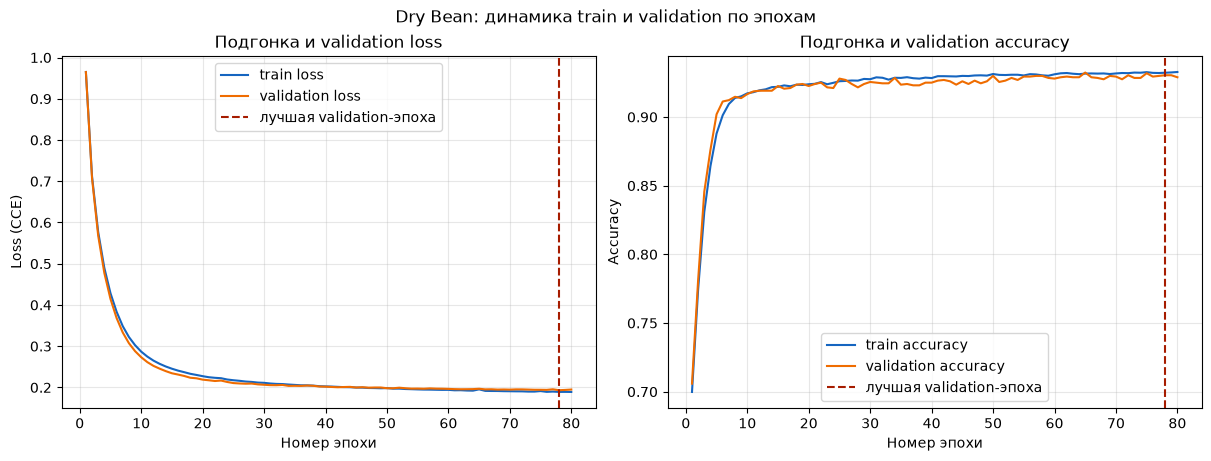

[Кривые обучения Dry Bean]
  panel_count: 2
  lines_per_panel: shape=(2,), value=[3 3]
  best_epoch_one_based: 78


In [16]:
# DRY_BEAN_MLP_EXAMPLE_CELL: plot_dry_bean_training_history
dry_bean_history_figure, dry_bean_history_axes = plot_training_history(
    dry_bean_history,
    "Dry Bean: динамика train и validation по эпохам",
)

assert len(dry_bean_history_axes) == 2
assert all(len(axis.lines) == 3 for axis in dry_bean_history_axes)
assert all(axis.get_xlabel() == "Номер эпохи" for axis in dry_bean_history_axes)
assert dry_bean_history.best_epoch + 1 == int(
    np.argmin(dry_bean_history.history["val_loss"])
) + 1
assert all(
    "test" not in line.get_label().lower()
    for axis in dry_bean_history_axes
    for line in axis.lines
)
plt.show()

show_step_result(
    "Кривые обучения Dry Bean",
    panel_count=len(dry_bean_history_axes),
    lines_per_panel=np.array([len(axis.lines) for axis in dry_bean_history_axes]),
    best_epoch_one_based=dry_bean_history.best_epoch + 1,
)

## Ячейка 17. Evaluation: независимый Dry Bean test

Блок `evaluate_dry_bean`.

После восстановления лучшего validation-checkpoint метрики вычисляются на train, validation и test. Test не передавался в `fit()` и не влияет на выбор архитектуры, эпохи или весов. Матрица ошибок имеет семь строк правильных классов и семь столбцов прогнозов.

**Контроль.** Проверяются accuracy, CCE, форма `(7, 7)` и сумма всех `2040` test-объектов.

In [17]:
# DRY_BEAN_MLP_EXAMPLE_CELL: evaluate_dry_bean
def confusion_matrix(labels, predictions, class_count):
    """Строит целочисленную confusion matrix.

    Args:
        labels (numpy.ndarray): Правильные классы формы ``(n,)``.
        predictions (numpy.ndarray): Предсказанные классы формы ``(n,)``.
        class_count (int): Число классов.

    Returns:
        numpy.ndarray: Матрица формы ``(class_count, class_count)``.
    """
    matrix = np.zeros((class_count, class_count), dtype=int)
    for target, prediction in zip(labels, predictions):
        matrix[int(target), int(prediction)] += 1
    return matrix


train_metrics = dry_bean_model.evaluate(features_train, labels_train)
validation_metrics = dry_bean_model.evaluate(
    features_validation, labels_validation
)
# Test вызывается единственный раз после восстановления лучшего checkpoint.
test_metrics = dry_bean_model.evaluate(features_test, labels_test)
test_predictions = dry_bean_model.predict(features_test)
test_confusion = confusion_matrix(labels_test, test_predictions, class_count=7)

print(
    f"train: loss={train_metrics['loss']:.6f}, "
    f"accuracy={train_metrics['accuracy']:.6f}"
)
print(
    f"validation: loss={validation_metrics['loss']:.6f}, "
    f"accuracy={validation_metrics['accuracy']:.6f}"
)
print(
    f"test: loss={test_metrics['loss']:.6f}, "
    f"accuracy={test_metrics['accuracy']:.6f}"
)
print("test confusion matrix:\n", test_confusion)

assert train_metrics["loss"] < 0.25
assert train_metrics["accuracy"] >= 0.90
assert validation_metrics["accuracy"] >= 0.90
assert test_metrics["accuracy"] >= 0.90
assert test_metrics["loss"] < 0.3
assert test_confusion.shape == (7, 7)
assert test_confusion.sum() == 2040
assert all(
    parameter.grad.shape == parameter.data.shape
    for parameter in dry_bean_model.parameters()
)

show_step_result(
    "Итоговая оценка Dry Bean",
    train_metrics=train_metrics,
    validation_metrics=validation_metrics,
    test_metrics=test_metrics,
    test_confusion=test_confusion,
)

train: loss=0.189171, accuracy=0.932221
validation: loss=0.193291, accuracy=0.930392
test: loss=0.189514, accuracy=0.928431
test confusion matrix:
 [[293   5   0   0   0   4   2]
 [  2 183   0   6   0   6   1]
 [  0   0  78   0   0   0   0]
 [  0   6   0 232   5   1   0]
 [  0   0   0   3 280   3   3]
 [  4   2   0   2   8 336  43]
 [  8   0   0   0   1  31 492]]
[Итоговая оценка Dry Bean]
  train_metrics: {'loss': 0.1891714157415375, 'accuracy': 0.9322211730143741}
  validation_metrics: {'loss': 0.19329058956583672, 'accuracy': 0.9303921568627451}
  test_metrics: {'loss': 0.18951421143107014, 'accuracy': 0.9284313725490196}
  test_confusion: shape=(7, 7), value=[[293   5 ...   4   2]
 [  2 183 ...   6   1]
 ...
 [  4   2 ... 336  43]
 [  8   0 ...  31 492]]


## Ячейка 18. Deployment: Dry Bean inference-bundle

Блок `serialize_model`.

`InferenceBundle` сохраняет архитектуру, активации, матрицы весов, train mean/std, порядок шестнадцати признаков и семь исходных названий классов. После загрузки отдельный batch сырых train-примеров должен дать те же вероятности и метки без повторного обучения.

In [18]:
# DRY_BEAN_MLP_EXAMPLE_CELL: serialize_model
class InferenceBundle:
    """Объединяет модель, подготовку входа и смысл выходных классов.

    Args:
        model (MLPClassifier): Обученная и выбранная модель.
        standardizer (Standardizer): Объект с train mean/std.
        feature_names (tuple[str, ...]): Ожидаемый порядок сырых признаков.
        class_labels (array-like): Исходные обозначения классов.

    Attributes:
        model (MLPClassifier): Модель для вычисления вероятностей.
        standardizer (Standardizer): Зафиксированное train-преобразование.
        feature_names (tuple[str, ...]): Контракт порядка признаков.
        class_labels (numpy.ndarray): Метки, возвращаемые пользователю.
    """

    def __init__(self, model, standardizer, feature_names, class_labels):
        """Проверяет и сохраняет компоненты inference-конвейера.

        Raises:
            ValueError: Если ширины модели, статистики и метки не согласованы.
        """
        if standardizer.mean is None or standardizer.standard_deviation is None:
            raise ValueError("Standardizer должен быть обучен на train")
        self.model = model
        self.standardizer = standardizer
        self.feature_names = tuple(feature_names)
        self.class_labels = np.asarray(class_labels).copy()
        if len(self.feature_names) != model.layer_sizes[0]:
            raise ValueError("Число имён признаков не равно входной ширине")
        if self.class_labels.shape != (model.layer_sizes[-1],):
            raise ValueError("Число меток классов не равно выходной ширине")

    def predict_raw(self, raw_features):
        """Выполняет inference от сырых признаков до вероятностей и меток.

        Args:
            raw_features (numpy.ndarray): Сырая матрица формы ``(n, d)``.

        Returns:
            tuple[numpy.ndarray, numpy.ndarray]: Вероятности формы ``(n, C)``
            и исходные метки предсказанных классов формы ``(n,)``.
        """
        standardized = self.standardizer.transform(raw_features)
        probabilities = self.model.predict_proba(standardized)
        predictions = self.class_labels[np.argmax(probabilities, axis=1)]
        return probabilities, predictions

    def save(self, path):
        """Сохраняет весь inference-контракт в безопасный NPZ.

        Args:
            path (str | pathlib.Path): Имя создаваемого файла.

        Returns:
            pathlib.Path: Путь к сохранённому bundle.
        """
        destination = Path(path)
        payload = {
            "format_version": np.array([1], dtype=int),
            "layer_sizes": np.array(self.model.layer_sizes, dtype=int),
            "hidden_activations": np.array(
                self.model.hidden_activations, dtype="U16"
            ),
            "feature_names": np.array(self.feature_names, dtype="U32"),
            "class_labels": self.class_labels,
            "feature_mean": self.standardizer.mean,
            "feature_standard_deviation": self.standardizer.standard_deviation,
        }
        for index, parameter in enumerate(self.model.parameters()):
            payload[f"weight_{index}"] = parameter.data
        np.savez(destination, **payload)
        return destination

    @classmethod
    def load(cls, path):
        """Восстанавливает новый inference-объект из NPZ.

        Args:
            path (str | pathlib.Path): Ранее созданный bundle.

        Returns:
            InferenceBundle: Новый готовый к прогнозу объект.

        Raises:
            ValueError: Если версия, число или формы матриц некорректны.
        """
        with np.load(Path(path), allow_pickle=False) as stored:
            version = int(stored["format_version"][0])
            if version != 1:
                raise ValueError(f"Неподдерживаемая версия bundle: {version}")
            layer_sizes = stored["layer_sizes"].astype(int).tolist()
            activations = stored["hidden_activations"].astype(str).tolist()
            model = MLPClassifier(layer_sizes, activations, seed=0)
            for index, parameter in enumerate(model.parameters()):
                weight = np.asarray(stored[f"weight_{index}"], dtype=float)
                if weight.shape != parameter.data.shape:
                    raise ValueError("Форма сохранённой матрицы не совпадает")
                parameter.data = weight.copy()

            fitted_standardizer = Standardizer()
            fitted_standardizer.mean = np.asarray(
                stored["feature_mean"], dtype=float
            ).copy()
            fitted_standardizer.standard_deviation = np.asarray(
                stored["feature_standard_deviation"], dtype=float
            ).copy()
            if np.any(fitted_standardizer.standard_deviation <= 0.0):
                raise ValueError("Сохранённые std должны быть положительными")

            feature_names = tuple(stored["feature_names"].astype(str).tolist())
            class_labels = np.asarray(stored["class_labels"]).copy()
        return cls(model, fitted_standardizer, feature_names, class_labels)


inference_bundle = InferenceBundle(
    dry_bean_model,
    standardizer,
    DRY_BEAN_FEATURE_NAMES,
    np.asarray(DRY_BEAN_CLASS_NAMES),
)
model_path = inference_bundle.save("dry_bean_mlp_model.npz")
loaded_bundle = InferenceBundle.load(model_path)

# Deployment-проверка использует отдельный небольшой batch, а не выполняет
# повторный выбор или настройку по закрытой test-выборке.
deployment_examples_raw = features_train_raw[:5].copy()
trained_probabilities, trained_predictions = inference_bundle.predict_raw(
    deployment_examples_raw
)
loaded_probabilities, loaded_predictions = loaded_bundle.predict_raw(
    deployment_examples_raw
)

assert model_path.is_file()
assert loaded_bundle.feature_names == DRY_BEAN_FEATURE_NAMES
assert np.array_equal(loaded_bundle.class_labels, np.asarray(DRY_BEAN_CLASS_NAMES))
assert np.allclose(loaded_bundle.standardizer.mean, train_mean)
assert np.allclose(
    loaded_bundle.standardizer.standard_deviation,
    train_standard_deviation,
)
assert np.allclose(loaded_probabilities, trained_probabilities)
assert np.array_equal(loaded_predictions, trained_predictions)

show_step_result(
    "Сериализация inference-bundle",
    saved_path=str(model_path),
    loaded_probabilities=loaded_probabilities,
    loaded_predictions=loaded_predictions,
)

[Сериализация inference-bundle]
  saved_path: dry_bean_mlp_model.npz
  loaded_probabilities: shape=(5, 7), value=[[1.074305e-03 3.120900e-04 ... 7.736006e-02 1.703217e-03]
 [1.229302e-02 7.198625e-03 ... 9.716512e-01 2.996669e-03]
 ...
 [2.222060e-04 3.298469e-05 ... 1.399281e-03 9.981472e-01]
 [6.495482e-05 5.651624e-05 ... 4.241378e-03 9.475237e-05]]
  loaded_predictions: shape=(5,), value=['HOROZ' 'SIRA' 'DERMASON' 'DERMASON' 'HOROZ']


## Итог

На крупном табличном наборе тот же алгоритм сохранил все существенные свойства: матрицы строят forward-DAG, callbacks получают входящие градиенты, mini-batch SGD обновляет параметры только по train, validation выбирает checkpoint, test остаётся независимым, а bundle делает inference воспроизводимым.

Теперь вернитесь к своей работе Wine: адаптируйте ячейки обучения, графиков, оценки и сериализации. Создайте новую модель с входом из 13 признаков и выходом из 3 классов; используйте только её данные, train-статистики и checkpoint.